# 3. Processing in chunks

In notebook 2, every step worked on one minute of data loaded in memory. A real-time system
cannot do that: data arrive in small packets, a fraction of a second each, and each packet
must be processed as soon as it arrives. Archives that do not fit in memory raise the same
problem.

In this notebook you will:
1. see why processing chunk by chunk breaks naive code,
2. turn the preprocessing into a pipeline of **atoms**, which carry their memory from one
   chunk to the next,
3. write your own atom: a continuous STA/LTA,
4. pick both cables over their whole record, chunk by chunk,
5. follow the location and magnitude of the earthquake from the stream of picks.

Notebook 4 plugs the same pipeline into a live stream.

In [1]:
# solutions only: run from the exercises folder
%cd ..

/Users/trabatto/pkgs/exercises


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sp
import xdas as xd
from xdas.atoms import Atom, Partial, State

from tools import EEWS, PeakAmplitude

**Task:** copy here the functions you wrote in notebook 2 (`remove_common_mode`,
`preprocess`, `to_displacement` and `stalta`). The rest of the cell loads the minute of the
north cable around the earthquake.

In [3]:
gain = 1536.6e-9 / (4 * np.pi * 1.4677 * 0.78)  # from notebook 2


def remove_common_mode(da):
    return da - da.median("distance")


def preprocess(da):
    da = remove_common_mode(da * gain)
    da = xd.filter(da, (2.0, 15.0), dim="time")
    da = xd.resample(da, interval=45.0, snap=True, dim="distance")
    return da


def to_displacement(da):
    strain = xd.integrate(da, dim="time")
    displacement = xd.integrate(strain, dim="distance")
    return xd.sliding_mean_removal(displacement, wlen=2000.0, dim="distance")


def stalta(da, sta, lta):
    dt = da["time"].get_sampling_interval()
    csta, clta = dt / sta, dt / lta
    power = da.values ** 2
    short = sp.lfilter([csta], [1, csta - 1], power, axis=0)
    long = sp.lfilter([clta], [1, clta - 1], power, axis=0)
    ratio = short / long
    ratio[: round(lta / dt)] = 0  # the long average is not settled yet
    return da.copy(data=ratio)


abyss = xd.open("abyss.nc")
event = abyss["N"].sel(time=slice("2024-09-02T02:56:00", "2024-09-02T02:57:00"), distance=slice(5000, 97000)).load()
displacement = to_displacement(preprocess(event))
ratio = stalta(displacement, sta=0.2, lta=5.0)

## The problem

Pretend the minute arrives in pieces of 10 s, one per file.

**Task:** split `displacement` into 6 chunks along time, apply `stalta` to each chunk, then put
the results back together. Plot it next to `ratio` (computed on the whole minute). What goes
wrong, and why?

> **Reminder:**
> ```python
> chunks = xd.split(da, 10, dim="x")     # a list of 10 arrays of (almost) equal size along "x"
> xd.concatenate(chunks, dim="x")        # back to one array
> [f(chunk) for chunk in chunks]         # apply f to each element of a list
> ```

📖 [`xdas.split`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.split.html) ·
[`xdas.concatenate`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.concatenate.html)

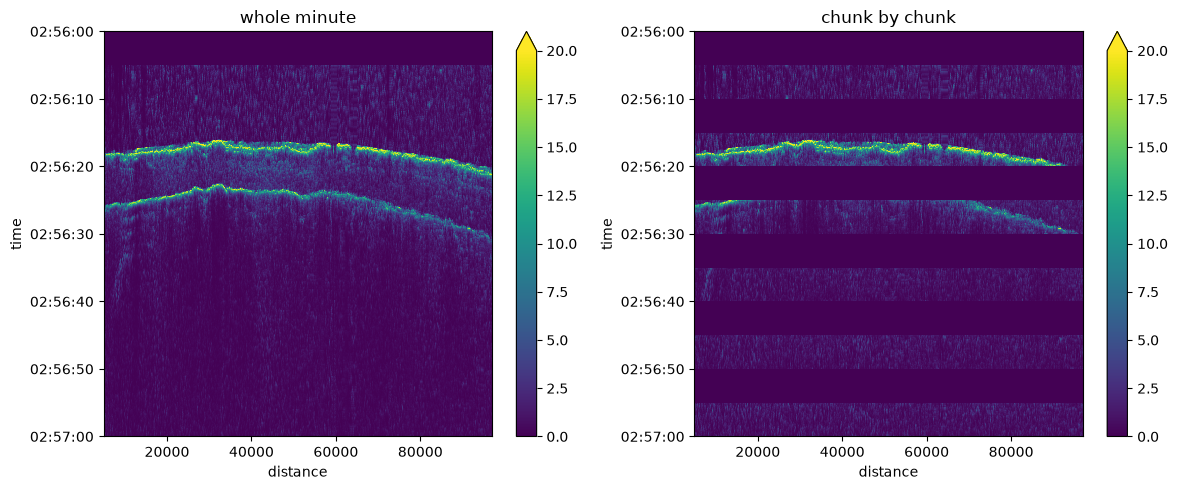

In [4]:
chunks = xd.split(displacement, 6, dim="time")
naive = xd.concatenate([stalta(chunk, sta=0.2, lta=5.0) for chunk in chunks], dim="time")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ratio.plot(ax=axes[0], vmin=0, vmax=20, yincrease=False)
naive.plot(ax=axes[1], vmin=0, vmax=20, yincrease=False)
axes[0].set_title("whole minute")
axes[1].set_title("chunk by chunk")
fig.tight_layout()

## Atoms

Each chunk starts from scratch: the averages restart from zero and the first 5 s of each
chunk are blanked. The filters and integrals before it have the same problem, only less
visible. The fix is to keep a **state**: what each step must remember from the previous chunk
(the last values of the averages, of the filters, of the integrals...).

Xdas does this with **atoms**. Every processing function also exists as an atom: call it with
`...` in place of the data, and it returns the step itself instead of a result. Atoms chain
with `>>` into a pipeline, which is called like a function. Called on chunks with
`chunk_dim="time"`, a pipeline keeps its state between calls.

**Task:** rewrite `preprocess` and `to_displacement` as a single pipeline of atoms.
`remove_common_mode` is your own function: it has no atom yet. It needs no memory (each time
sample is handled on its own), so `Partial` can wrap it into one. So can the gain:
`Partial(np.multiply, gain)` multiplies what it is given by `gain`.

> **Reminder:**
> ```python
> xd.filter(da, (1.0, 5.0), dim="x")         # a function: filters da now
> xd.filter(..., (1.0, 5.0), dim="x")        # an atom: will filter what it is given later
> Partial(f)                                 # an atom from your own function f(da), without memory
> pipeline = atom1 >> atom2 >> atom3         # chain atoms (wrap long chains in parentheses)
> pipeline(da)                               # run it on a whole array
> pipeline(chunk, chunk_dim="x")             # run it on the next chunk along "x"
> ```

📖 [Composing a processing sequence](https://xdas.readthedocs.io/en/stable/user-guide/pipeline/atoms.html)

In [5]:
pipeline = (
    Partial(np.multiply, gain)
    >> Partial(remove_common_mode)
    >> xd.filter(..., (2.0, 15.0), dim="time")
    >> xd.resample(..., interval=45.0, snap=True, dim="distance")
    >> xd.integrate(..., dim="time")
    >> xd.integrate(..., dim="distance")
    >> xd.sliding_mean_removal(..., wlen=2000.0, dim="distance")
)
pipeline

Sequential:
  0: multiply(..., 1.0681175917797704e-07)
  1: remove_common_mode(...)
  2: Filter(freq=(2.0, 15.0))
  3: Resample(interval=45.0, snap=True, dim='distance')
  4: Integrate()
  5: Integrate(dim='distance')
  6: sliding_mean_removal(..., wlen=2000.0, dim='distance')

Instead of writing the loop over chunks, `.process` does it for you: it cuts the input into
chunks, feeds them to the pipeline in order and joins the results.

**Task:** run `pipeline` on `event` by chunks of 100 samples, and check that the result is the
same as `displacement`.

> **Reminder:**
> ```python
> result = pipeline.process(da, chunks={"x": 100})   # chunks of 100 samples along "x"
> np.abs(a.values - b.values).max()                  # largest difference between two arrays
> ```

📖 [Processing larger-than-memory data](https://xdas.readthedocs.io/en/stable/user-guide/pipeline/processing.html)

In [6]:
chunked = pipeline.process(event, chunks={"time": 100})
np.abs(chunked.values - displacement.values).max()

100%|██████████| 137M/137M [00:01<00:00, 121MB/s, read=2.3%, proc=97.7%, write=0.0%]   


np.float64(5.421010862427522e-20)

## A continuous STA/LTA

Our `stalta` has no atom yet: let us write it. An atom is a class with three methods:
- `__init__` stores the parameters, and declares each state as `State(...)` (not known yet);
- `initialize` is called on the first chunk: it sets the initial states;
- `call` processes one chunk, using the states and updating them.

The recursion of notebook 2 only needs the last value of each average, which `sp.lfilter` can
take as an input (`zi`) and give back as an output (`zf`). The number of samples already seen
tells which samples still lie in the first `lta` seconds, where the ratio is blanked.

The states, and where they start:
- `short` and `long`: the last value of each average, one per channel, as an array of shape
  (1, number of channels) (the shape `zi` wants). They start at 0, which is what `sp.lfilter`
  assumes without `zi`: the result then matches notebook 2;
- `count`: the number of samples already seen, 0 at the start.

**Task:** complete `initialize` with these initial states, and `call`: run the two recursions
starting from the stored states, then store the new states.

> **Reminder:**
> ```python
> y, zf = sp.lfilter(b, a, x, axis=0, zi=zi)  # zi: state before x, zf: state after x
>                                              # (zi of shape (1, n channels) for our filters)
> self.thing = State(new_value)                # update a state (always with State)
> self.thing                                   # read a state
> np.zeros((1, n))                             # an array of zeros, of shape (1, n)
> da.sizes["distance"]                         # the number of channels
> ```

📖 [Defining custom atoms](https://xdas.readthedocs.io/en/stable/user-guide/pipeline/atoms.html#defining-custom-atoms)

In [7]:
class STALTA(Atom):
    def __init__(self, sta, lta):
        super().__init__()
        self.sta = sta
        self.lta = lta
        self.short = State(...)
        self.long = State(...)
        self.count = State(...)

    def initialize(self, da, **flags):
        self.short = State(np.zeros((1, da.sizes["distance"])))
        self.long = State(np.zeros((1, da.sizes["distance"])))
        self.count = State(0)

    def call(self, da, **flags):
        dt = da["time"].get_sampling_interval()
        csta, clta = dt / self.sta, dt / self.lta
        power = da.values ** 2
        short, zshort = sp.lfilter([csta], [1, csta - 1], power, axis=0, zi=self.short)
        long, zlong = sp.lfilter([clta], [1, clta - 1], power, axis=0, zi=self.long)
        self.short = State(zshort)
        self.long = State(zlong)
        ratio = short / long
        ratio[: max(round(self.lta / dt) - self.count, 0)] = 0  # the long average is not settled yet
        self.count = State(self.count + len(ratio))
        return da.copy(data=ratio)

**Task:** run your atom on the 6 chunks of `displacement`, one call per chunk (it has to keep
its state: pass `chunk_dim`), put the results together and compare with `ratio`.

In [8]:
atom = STALTA(sta=0.2, lta=5.0)
continuous = xd.concatenate([atom(chunk, chunk_dim="time") for chunk in chunks], dim="time")
np.abs(continuous.values - ratio.values).max()

np.float64(0.0)

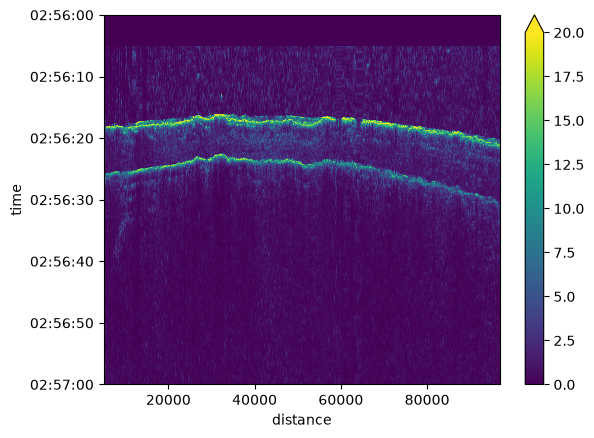

In [9]:
continuous.plot(vmin=0, vmax=20, yincrease=False)

## The whole record

Your atom now fits in the pipeline, followed by the trigger: `xd.trigger` also exists as an
atom, which outputs tables of picks.

For the magnitude, each pick also needs the peak of its P wave, as in notebook 2.
`PeakAmplitude` (in `tools.py`) measures it on a stream: it wraps the detector (STA/LTA then
trigger), keeps the last seconds of displacement, and gives each pick an `amplitude` column once
2 s of data have arrived after it.

**Task:** build the full pipeline (preprocessing and displacement, then STA/LTA and trigger
wrapped in `PeakAmplitude`) and run it on both cables, over their whole 4 min record. As in notebook 2, keep only the channels in the sea.

> **Reminder:**
> - a `DataCollection` can be built from a dict: `xd.DataCollection({"a": da1, "b": da2}, "name")`;
>   `"name"` names the level (here: the cable);
> - `.process` on a collection runs each array in turn (each with a fresh state), and returns one
>   table for all, with one column per level of the collection;
> - without `chunks`, `.process` follows the files on disk: one chunk per file (10 s);
> - `PeakAmplitude(detector, window=2.0)` wraps an atom or a pipeline.

📖 [`xdas.trigger`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.trigger.html)

In [10]:
keep = {"N": slice(5000, 97000), "S": slice(5000, 130000)}
sea = xd.DataCollection({cable: abyss[cable].sel(distance=keep[cable]) for cable in abyss}, "cable")

picker = pipeline >> PeakAmplitude(
    STALTA(sta=0.2, lta=5.0) >> xd.trigger(..., thresh=8.0, coords=["distance", "longitude", "latitude", "depth", "time"]),
    window=2.0,
)
picks = picker.process(sea)
picks

100%|██████████| 550M/550M [00:04<00:00, 126MB/s, read=16.4%, proc=83.6%, write=0.1%] 
100%|██████████| 467M/467M [00:03<00:00, 159MB/s, read=22.7%, proc=77.3%, write=0.0%]


,cable,distance,longitude,latitude,depth,time,value,amplitude
0,N,5009.477436,-71.278298,-29.888062,5.8,2024-09-02 02:56:25.880,18.174203,3.043932e-06
1,N,5055.435944,-71.278752,-29.887957,6.2,2024-09-02 02:55:46.520,8.907972,1.411534e-07
2,N,5055.435944,-71.278752,-29.887957,6.2,2024-09-02 02:56:25.880,16.456949,2.061548e-06
3,N,5101.394453,-71.279206,-29.887853,6.6,2024-09-02 02:56:25.870,15.802452,1.819647e-06
4,N,5147.352962,-71.279661,-29.887748,7.1,2024-09-02 02:56:25.910,11.548377,9.278007e-07
...,...,...,...,...,...,...,...,...
10854,S,128867.658072,-71.841693,-30.709930,1777.6,2024-09-02 02:58:41.424,14.510428,2.828606e-07
10855,S,128913.616581,-71.841734,-30.710334,1760.9,2024-09-02 02:58:41.424,13.786487,2.420853e-07
10856,S,128959.575089,-71.841775,-30.710738,1744.3,2024-09-02 02:58:41.424,12.500512,1.872339e-07
10857,S,129005.533598,-71.841816,-30.711142,1727.7,2024-09-02 02:58:41.504,11.445800,1.503031e-07


Text(0.5, 0, 'time')

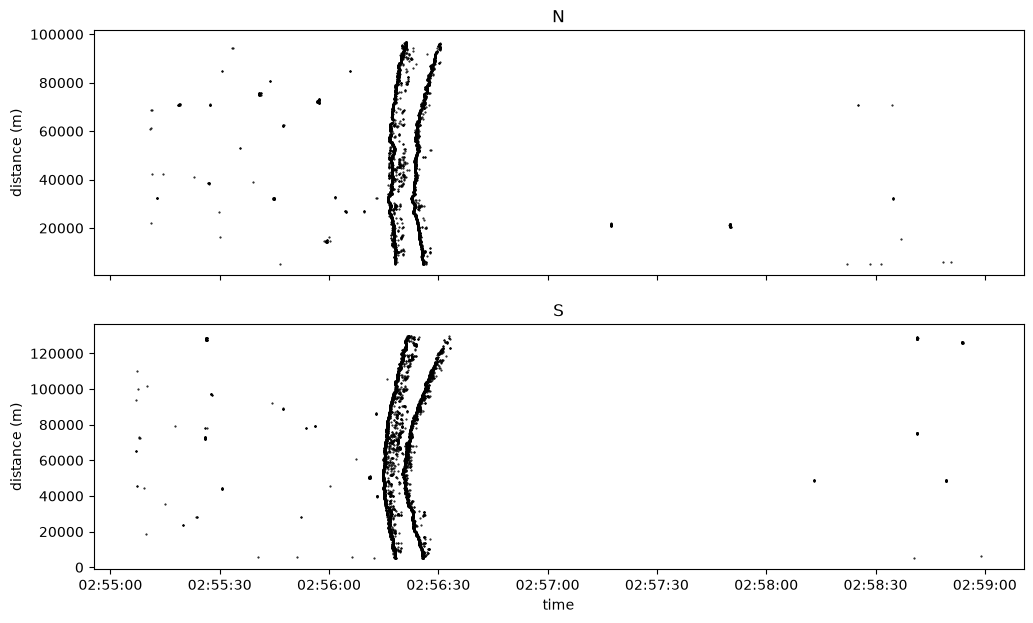

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, (cable, table) in zip(axes, picks.groupby("cable")):
    ax.plot(table["time"], table["distance"], "k.", markersize=1)
    ax.set_title(cable)
    ax.set_ylabel("distance (m)")
axes[1].set_xlabel("time")

## Early warning from a stream of picks

In a stream, picks come a few at a time, and nobody tells us when an earthquake starts or ends.
`EEWS` (in `tools.py`: an earthquake early-warning system) is called with the new picks and the
current time. It keeps the picks of the last 10 s, one per channel: once a channel has picked,
its picks of the next 20 s (S wave, coda) are ignored. Every second, if more than 1000 channels
have picked, it locates the earthquake and estimates its magnitude from the P amplitudes (with
the S/P ratio calibrated in notebook 2); otherwise its solution is NaN. Called again and again,
it gives a stream of solutions: how the solution evolves while the waves cross the cables.

**Task:** replay the picks second by second: at each step, give `eews` the picks of the last
second, and keep the solutions it returns. When does the first solution come, compared with
the origin time? How long until it settles? Compare with notebook 2 and with EMSC.

> **Reminder:**
> ```python
> pd.date_range("2024-01-01T00:00:00", "2024-01-01T00:01:00", freq="1s")  # times every second
> pd.Timedelta(seconds=1)                            # a duration
> table[(table["time"] >= a) & (table["time"] < b)]  # the rows between two times
> pd.concat(list_of_tables, ignore_index=True)       # stack tables
> ```

In [12]:
eews = EEWS()
solutions = []
for now in pd.date_range("2024-09-02T02:55:00", "2024-09-02T02:59:10", freq="1s"):
    new = picks[(picks["time"] >= now - pd.Timedelta(seconds=1)) & (picks["time"] < now)]
    solutions.append(eews(new, now))
solutions = pd.concat(solutions, ignore_index=True)
solutions.dropna()

,time,origin,longitude,latitude,depth,magnitude,picks
76,2024-09-02 02:56:16,2024-09-02 02:55:59.220000000,-72.20,-29.75,95000.0,3.897393,1003
77,2024-09-02 02:56:17,2024-09-02 02:56:07.209999999,-71.80,-30.00,55000.0,3.528862,2006
78,2024-09-02 02:56:18,2024-09-02 02:56:09.379999999,-71.75,-30.05,40000.0,3.463822,3153
79,2024-09-02 02:56:19,2024-09-02 02:56:07.929999999,-71.90,-29.95,45000.0,3.581025,3877
80,2024-09-02 02:56:20,2024-09-02 02:56:07.899999999,-71.90,-29.95,45000.0,3.582227,4198
81,2024-09-02 02:56:21,2024-09-02 02:56:07.903999999,-71.90,-29.95,45000.0,3.597507,4477
82,2024-09-02 02:56:22,2024-09-02 02:56:07.923999999,-71.90,-29.95,45000.0,3.604883,4624
83,2024-09-02 02:56:23,2024-09-02 02:56:07.926000000,-71.90,-29.95,45000.0,3.605415,4628
84,2024-09-02 02:56:24,2024-09-02 02:56:07.926000000,-71.90,-29.95,45000.0,3.605676,4635
85,2024-09-02 02:56:25,2024-09-02 02:56:07.926000000,-71.90,-29.95,45000.0,3.611141,4679


The evolution of the solution, against EMSC (dashed).

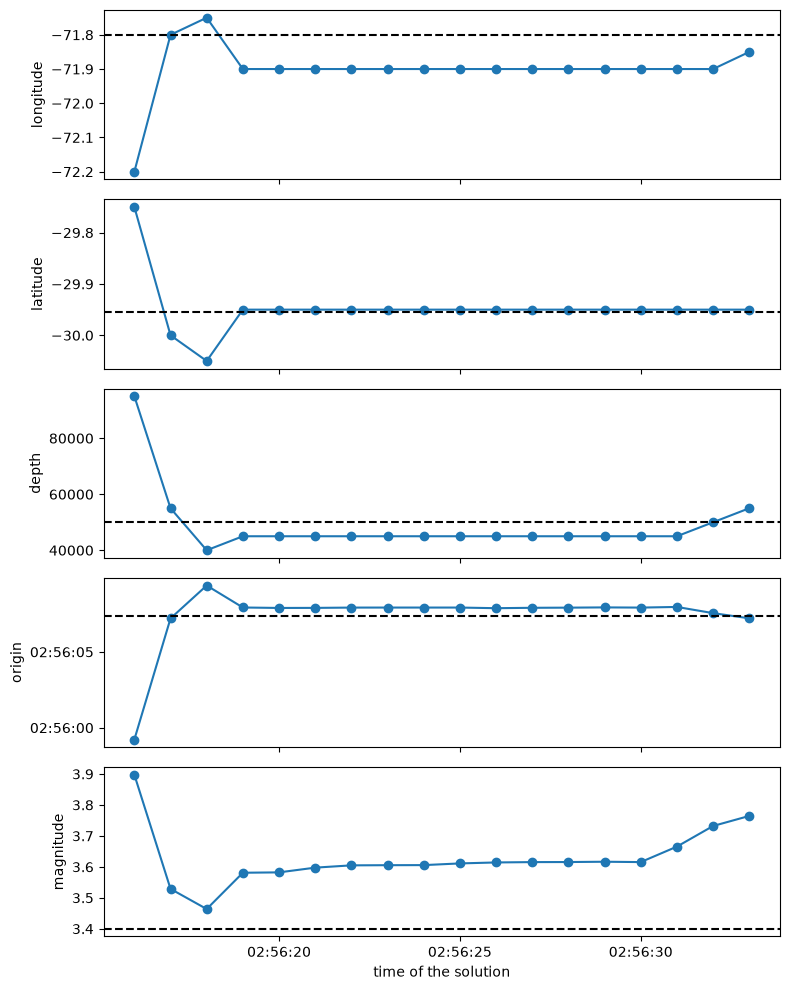

In [13]:
found = solutions.dropna()
emsc = {
    "longitude": -71.800,
    "latitude": -29.954,
    "depth": 50000.0,
    "origin": pd.Timestamp("2024-09-02T02:56:07.37"),
    "magnitude": 3.4,
}
fig, axes = plt.subplots(len(emsc), 1, figsize=(8, 10), sharex=True)
for ax, (key, value) in zip(axes, emsc.items()):
    ax.plot(found["time"], found[key], "o-")
    ax.axhline(value, color="k", linestyle="--")
    ax.set_ylabel(key)
axes[-1].set_xlabel("time of the solution")
fig.tight_layout()